In [1]:
!pip install --upgrade binance-historical-data plotly -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 57.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 272.8/272.8 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 36.1 MB/s eta 0:00:00


In [2]:
import os
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime, timedelta, date, time
from binance_historical_data import BinanceDataDumper
warnings.filterwarnings('ignore')

def get_list_all_trading_pairs():
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",  # spot, um, cm
        data_type="klines",  # aggTrades, klines, trades
        data_frequency="5m",
    )
    return data_dumper.get_list_all_trading_pairs()

def detect_timestamp_unit(timestamp):
    num_digits = len(str(timestamp))
    if num_digits == 13:
        return 'ms'
    elif num_digits == 16:
        return 'us'
    else:
        raise ValueError(f"Timestamp không hợp lệ: {timestamp}")

def convert_timestamp(timestamp):
    unit = detect_timestamp_unit(timestamp)
    return pd.to_datetime(timestamp, unit=unit, errors='coerce')

def download_ticker(ticker, date_start, date_end, data_frequency="1h"):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency= data_frequency,
    )
    date_start = datetime.strptime(date_start, "%Y-%m-%d").date()
    date_end = datetime.strptime(date_end, "%Y-%m-%d").date()
    data_dumper.dump_data(
        tickers = ticker,
        date_start = date_start,
        date_end = date_end,
        is_to_update_existing = False,
    )

def read_csv_file(file_path):
    df = pd.read_csv(file_path)
    df.columns = [
        "open_time", "Open", "High", "Low", "Close", "volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]
    df['open_time'] = df['open_time'].apply(convert_timestamp)
    df['close_time'] = df['close_time'].apply(convert_timestamp)
    return df

def get_csv_files(directory):
    try:
        if not os.path.exists(directory):
            print(f"Warning: Thư mục không tồn tại: {directory}")
            return []
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.csv')]
    except Exception as e:
        print(f"Lỗi khi đọc thư mục {directory}: {str(e)}")
        return []

# Load data from file
def process_csv_files(ticker, data_frequency = "1h"):
    daily_path = os.path.join(os.getcwd(), f"spot/daily/klines/{ticker}/{data_frequency}")
    monthly_path = os.path.join(os.getcwd(), f"spot/monthly/klines/{ticker}/{data_frequency}")
    daily_files = get_csv_files(daily_path)
    monthly_files = get_csv_files(monthly_path)
    all_files = daily_files + monthly_files
    if not all_files:
        print(f"❗ Không có file CSV nào cho {ticker}")
        return None
    data = pd.concat([read_csv_file(file) for file in all_files], ignore_index=True)
    data.sort_values(by='open_time', inplace=True)
    return data



In [13]:
ticker = 'PAXGUSDT'
data_frequency = '15m'
download_ticker(ticker, "2022-01-01", "2024-07-25", data_frequency)
df = process_csv_files(ticker, data_frequency)
df = df.drop(columns=['close_time',	'quote_asset_volume',	'number_of_trades',	'taker_buy_base_asset_volume',	'taker_buy_quote_asset_volume',	'ignore'])
df.set_index('open_time', inplace=True)
df

---> Found overall tickers: 601
---> Filter to asked tickers: 8
------> Tickers left: 3
Download full data for 3 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 15m
---> Start Date: 20220101
---> End Date: 20240725


Tickers:   0%|          | 0/3 [00:00<?, ?it/s]

monthly files to download:   0%|          | 0/30 [00:00<?, ?files/s]

daily files to download:   0%|          | 0/25 [00:00<?, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download:   0%|          | 0/25 [00:00<?, ?files/s]

Tried to dump data for 3 tickers:
---> For PAXGUSDT new data saved for: 30 months 25 days
---> For PAXGUSD new data saved for: 0 months 0 days
---> For GUSDT new data saved for: 0 months 7 days


,Open,High,Low,Close,volume
open_time,,,,,
2022-01-01 00:15:00,1835.0,1837.0,1835.0,1836.0,3.8410
2022-01-01 00:30:00,1836.0,1836.0,1834.0,1836.0,8.0970
2022-01-01 00:45:00,1836.0,1838.0,1835.0,1838.0,13.8929
2022-01-01 01:00:00,1838.0,1838.0,1837.0,1838.0,3.3468
2022-01-01 01:15:00,1838.0,1838.0,1837.0,1838.0,5.5874
...,...,...,...,...,...
2024-07-25 22:45:00,2369.0,2372.0,2365.0,2372.0,4.1796
2024-07-25 23:00:00,2370.0,2370.0,2367.0,2368.0,1.0650
2024-07-25 23:15:00,2369.0,2374.0,2366.0,2374.0,5.8079


In [14]:
# Calculate moving average for prices
short_window = 20    #Adjust params here
long_window = 50
df['MA_long'] = df['Close'].rolling(window=long_window).mean()
df['MA_short'] = df['Close'].rolling(window=short_window).mean()

# Position
df['Position'] = np.select((
    (df['MA_short'] > df['MA_long']) & (df['MA_short'].shift(1) < df['MA_long'].shift(1)),
    (df['MA_short'] < df['MA_long']) & (df['MA_short'].shift(1) > df['MA_long'].shift(1))),
                           (1, -1),
                           default=0)
df['Position'] = df['Position'].replace(0, method='ffill')

df.head(100)

,Open,High,Low,Close,volume,MA_long,MA_short,Position
open_time,,,,,,,,
2022-01-01 00:15:00,1835.0,1837.0,1835.0,1836.0,3.8410,NaN,NaN,0
2022-01-01 00:30:00,1836.0,1836.0,1834.0,1836.0,8.0970,NaN,NaN,0
2022-01-01 00:45:00,1836.0,1838.0,1835.0,1838.0,13.8929,NaN,NaN,0
2022-01-01 01:00:00,1838.0,1838.0,1837.0,1838.0,3.3468,NaN,NaN,0
2022-01-01 01:15:00,1838.0,1838.0,1837.0,1838.0,5.5874,NaN,NaN,0
...,...,...,...,...,...,...,...,...
2022-01-02 00:00:00,1837.0,1837.0,1836.0,1836.0,0.1290,1836.24,1836.00,-1
2022-01-02 00:15:00,1836.0,1837.0,1836.0,1837.0,1.6358,1836.26,1836.00,-1
2022-01-02 00:30:00,1836.0,1838.0,1835.0,1838.0,3.4260,1836.28,1836.10,-1


In [15]:
def calculate_returns(pos,close):
  entry = [0] * len(pos)
  pnls = [0] * len(pos)
  fee = 0.05/100
  for i in range (1,len(pos)):
    if pos[i] == pos[i-1]:
      entry[i] = entry[i-1]
    elif pos[i] != pos[i-1]:
      entry[i] = close[i]

  for i in range (1,len(pos)):
    if entry[i] != entry[i-1]:
      pnls[i] = (entry[i] - entry[i-1])*pos[i-1]*(1-fee)

  return entry, pnls

df['Price'], df['Pnls'] = calculate_returns(df['Position'], df['Close'])


df.head (500) # Display the DataFrame

,Open,High,Low,Close,volume,MA_long,MA_short,Position,Price,Pnls
open_time,,,,,,,,,,
2022-01-01 00:15:00,1835.0,1837.0,1835.0,1836.0,3.8410,NaN,NaN,0,0.0,0.0
2022-01-01 00:30:00,1836.0,1836.0,1834.0,1836.0,8.0970,NaN,NaN,0,0.0,0.0
2022-01-01 00:45:00,1836.0,1838.0,1835.0,1838.0,13.8929,NaN,NaN,0,0.0,0.0
2022-01-01 01:00:00,1838.0,1838.0,1837.0,1838.0,3.3468,NaN,NaN,0,0.0,0.0
2022-01-01 01:15:00,1838.0,1838.0,1837.0,1838.0,5.5874,NaN,NaN,0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
2022-01-06 04:00:00,1816.0,1816.0,1811.0,1814.0,27.6805,1820.10,1817.25,-1,1815.0,0.0
2022-01-06 04:15:00,1815.0,1815.0,1814.0,1814.0,1.2958,1819.84,1817.00,-1,1815.0,0.0
2022-01-06 04:30:00,1815.0,1816.0,1814.0,1815.0,13.3592,1819.62,1816.85,-1,1815.0,0.0


In [16]:
count_positive = (df['Pnls'] > 0).sum()
sum_positive = df[df['Pnls'] > 0]['Pnls'].sum()

count_negative = (df['Pnls'] < 0).sum()
sum_negative = df[df['Pnls'] < 0]['Pnls'].sum()

print(f'Số lệnh lãi: {count_positive}')
print(f'Số lệnh lỗ: {count_negative}')
print(f'Tổng lãi: {sum_positive}')
print(f'Lãi trung bình: {sum_positive/count_positive}')
print(f'Tổng lỗ: {sum_negative}')
print(f'Lỗ trung bình: {sum_negative/count_negative}')

Số lệnh lãi: 566
Số lệnh lỗ: 1283
Tổng lãi: 5506.245500000001
Lãi trung bình: 9.72834893992933
Tổng lỗ: -6995.5005
Lỗ trung bình: -5.4524555728760715


In [17]:
def longest_negative_streak(data):
    arr = np.array(data)

    # Mask for negatives
    neg_mask = arr < 0

    # Split into groups where non-negatives break the streak
    streaks = np.split(arr[neg_mask], np.where(~neg_mask)[0])

    # Filter out empty arrays
    streaks = [s for s in streaks if len(s) > 0]

    if not streaks:
        return 0, 0, []

    # Longest streak (by length)
    longest = max(streaks, key=len)
    longest_count = len(longest)

    # Streak with the highest sum (least negative)
    highest_sum_streak = max(streaks, key=np.sum)
    highest_sum = highest_sum_streak.sum()

    return longest_count, highest_sum, longest.tolist()


data = [-3,0,2,3,4,-5,-6,-2,8,4,3,0,0,4,-2,-8,0,-3,-6,-7]
longest_negative_streak(data)






(4, np.int64(-2), [-2, -8, -3, -6])

In [18]:
def longest_negative_streak(data):
    current = []
    count_list = []
    total_list = []
    # average = []      # Dùng numpy để tính cái này sau
    total = 0
    count = 0
    longest_count = 0
    highest_sum = 0

    for num in data:
        if num < 0:
            current.append(num)
        else:
          if current != []:
            count = len(current)
            total = sum(current)
            count_list.append(count)
            total_list.append(total)
            if abs(total) > abs(highest_sum):
              highest_sum = total
            if count > longest_count:
              longest_count = count
              longest = current

            current = []
            count = 0
            total = 0

    return count, highest_sum


pnls = df['Pnls'].tolist()
pnls_no_0 = [x for x in pnls if x != 0]
print("Longest negative streak:", longest_negative_streak(pnls_no_0))
print("Longest negative streak:", longest_negative_streak(pnls_no_0))


Longest negative streak: (0, -145.92700000000002)
Longest negative streak: (0, -145.92700000000002)


In [21]:
def find_negative_streaks(arr):
    """
    Find all negative streaks in an array.

    Args:
        arr (list): Input array of numbers

    Returns:
        list: List of lists, each sublist containing a negative streak
    """
    if not arr:
        return []

    negative_streaks = []
    current_streak = []

    for num in arr:
        if num > 0:
            current_streak.append(num)
        else:
            if current_streak:
                negative_streaks.append(current_streak.copy())
                current_streak = []

    # Don't forget the last streak if it ends at the end of array
    if current_streak:
        negative_streaks.append(current_streak)

    return negative_streaks

def find_longest_negative_streak(arr):
    """
    Find the longest negative streak in the array.

    Args:
        arr (list): Input array of numbers

    Returns:
        list: The longest negative streak, or empty list if none found
    """
    all_streaks = find_negative_streaks(arr)
    if not all_streaks:
        return []

    return max(all_streaks, key=len)

def calculate_streak_stats(arr):
    """
    Calculate statistics for all negative streaks.

    Args:
        arr (list): Input array of numbers

    Returns:
        dict: Dictionary containing sum, min_sum, max_sum, and mean_sum of streaks
    """
    streaks = find_negative_streaks(arr)

    if not streaks:
        return {
            'sum': 0,
            'min_sum': 0,
            'max_sum': 0,
            'mean_sum': 0,
            'num_streaks': 0
        }

    streak_sums = [sum(streak) for streak in streaks]

    return {
        'sum': sum(streak_sums),
        'min_sum': min(streak_sums),
        'max_sum': max(streak_sums),
        'mean_sum': sum(streak_sums) / len(streak_sums),
        'num_streaks': len(streaks)
    }

def analyze_negative_streaks(arr):
    """
    Complete analysis of negative streaks in an array.

    Args:
        arr (list): Input array of numbers

    Returns:
        dict: Comprehensive analysis results
    """
    if not arr:
        return {
            'all_streaks': [],
            'longest_streak': [],
            'stats': {
                'sum': 0,
                'min_sum': 0,
                'max_sum': 0,
                'mean_sum': 0,
                'num_streaks': 0
            }
        }

    all_streaks = find_negative_streaks(arr)
    longest_streak = find_longest_negative_streak(arr)
    stats = calculate_streak_stats(arr)

    return {
        'all_streaks': all_streaks,
        'longest_streak': longest_streak,
        'stats': stats
    }

# Example usage and testing
if __name__ == "__main__":
    # Test arrays
    # test_array = [1, -2, -3, 4, -5, -6, -7, 8, 9, -10, 11]
    test_array = pnls_no_0
    print("Input array:", test_array)
    print("\n--- Analysis Results ---")

    # Get all negative streaks
    streaks = find_negative_streaks(test_array)
    print(f"All negative streaks: {streaks}")

    # Get longest negative streak
    longest = find_longest_negative_streak(test_array)
    print(f"Longest negative streak: {longest} (length: {len(longest)})")

    # Get statistics
    stats = calculate_streak_stats(test_array)
    print(f"\n--- Streak Statistics ---")
    print(f"Total sum of all streaks: {stats['sum']}")
    print(f"Minimum streak sum: {stats['min_sum']}")
    print(f"Maximum streak sum: {stats['max_sum']}")
    print(f"Mean streak sum: {stats['mean_sum']:.2f}")
    print(f"Number of streaks: {stats['num_streaks']}")

    # Complete analysis
    print(f"\n--- Complete Analysis ---")
    analysis = analyze_negative_streaks(test_array)
    print(analysis)

Input array: [0.9995, -1.999, -2.9985, -1.999, -0.9995, 0.9995, 0.9995, -1.999, -1.999, -1.999, 22.988500000000002, -5.997, -14.992500000000001, -3.998, -1.999, -2.9985, 17.991, -3.998, -1.999, 3.998, -2.9985, -5.997, -4.9975000000000005, -3.998, -2.9985, -2.9985, -4.9975000000000005, 19.990000000000002, -6.9965, 2.9985, 5.997, 2.9985, 3.998, -0.9995, -0.9995, -1.999, -3.998, -3.998, -3.998, -7.996, -6.9965, -5.997, 0.9995, 28.985500000000002, -1.999, -4.9975000000000005, -1.999, -8.9955, -10.9945, -8.9955, -3.998, -1.999, -2.9985, -5.997, -3.998, -2.9985, -6.9965, -6.9965, -8.9955, -1.999, -6.9965, -1.999, 43.978, -3.998, 4.9975000000000005, -3.998, -1.999, 0.9995, 4.9975000000000005, -1.999, 5.997, 0.9995, -3.998, -0.9995, -0.9995, -1.999, -0.9995, 6.9965, -18.9905, -1.999, -0.9995, -3.998, 3.998, 37.981, -3.998, 0.9995, 8.9955, -4.9975000000000005, 2.9985, -4.9975000000000005, -6.9965, 46.9765, -3.998, 1.999, -3.998, -2.9985, -7.996, 9.995000000000001, -14.992500000000001, -27.986, 

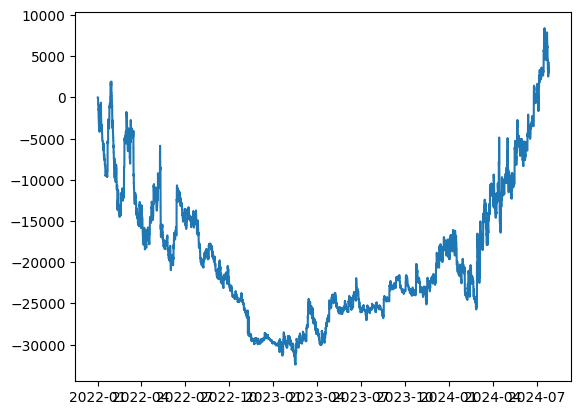

In [9]:
dates = df.index.tolist()

# Plot profit
# plt.plot(unrealised_dates, np.cumprod(1+np.array(unrealised))-1)
# plt.plot(dates, np.cumprod(1+np.array(pnls))-1)
#plt.plot(dates,np.cumprod(1+np.array(pnls))-1)
# plt.plot(unrlzd_dates,np.cumprod(1+np.array(unrlzd)))
plt.plot(dates, np.cumsum(pnls))
#plt.plot(unrlzd_dates, np.cumsum(unrlzd))